In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry curly hair data/Extension_Dry_200mmmin_C.csv")
print(df)

     Record  Strain (%)  Stress (MPa)
0         1         0.0           0.1
1         1         0.0          -0.1
2         1         0.0           0.0
3         1         0.0           0.0
4         1         0.0          -0.1
..      ...         ...           ...
870      25         3.1           1.4
871      25         3.3           1.4
872      25         3.5           1.4
873      25         3.7           2.0
874      25         4.0           2.3

[875 rows x 3 columns]


In [18]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

     Record  Strain (%)  Stress (MPa)
0         1         0.0           0.1
1         1         0.0          -0.1
2         1         0.0           0.0
3         1         0.0           0.0
600      18         0.0          -0.1
<class 'pandas.core.frame.DataFrame'>
Index: 875 entries, 0 to 874
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        875 non-null    int64  
 1   Strain (%)    875 non-null    float64
 2   Stress (MPa)  875 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 27.3 KB
None


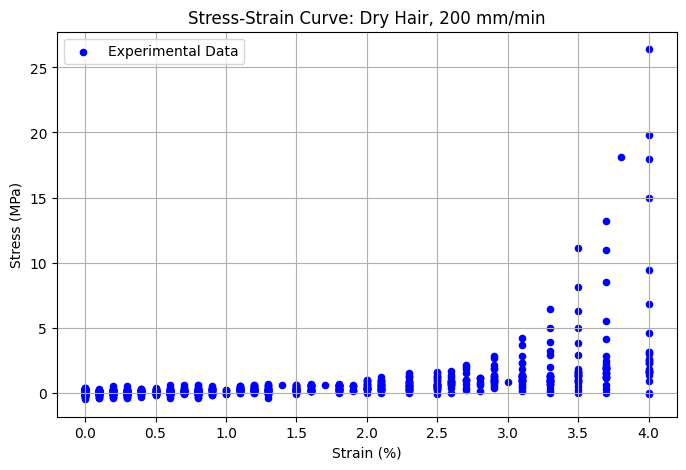

In [19]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 200 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)          mean       std
0          0.0  1.266667e-02  0.149404
1          0.1 -1.800000e-02  0.150767
2          0.2  2.000000e-02  0.193725
3          0.3  6.938894e-19  0.179743
4          0.4  7.200000e-02  0.148661
5          0.5  6.000000e-02  0.152753
6          0.6  5.483871e-02  0.199731
7          0.7  1.250000e-01  0.162186
8          0.8  8.181818e-02  0.206040
9          0.9  1.450000e-01  0.203845
10         1.0  5.000000e-02  0.137840
11         1.1  2.520000e-01  0.153080
12         1.2  2.800000e-01  0.180278
13         1.3  1.916667e-01  0.253526
14         1.4  6.000000e-01       NaN
15         1.5  2.720000e-01  0.201080
16         1.6  3.375000e-01  0.210202
17         1.7  6.000000e-01       NaN
18         1.8  3.720000e-01  0.198997
19         1.9  3.500000e-01  0.207364
20         2.0  5.105263e-01  0.276676
21         2.1  5.280000e-01  0.304850
22         2.3  6.080000e-01  0.387212
23         2.5  7.080000e-01  0.420238
24         2.6  8.266667e

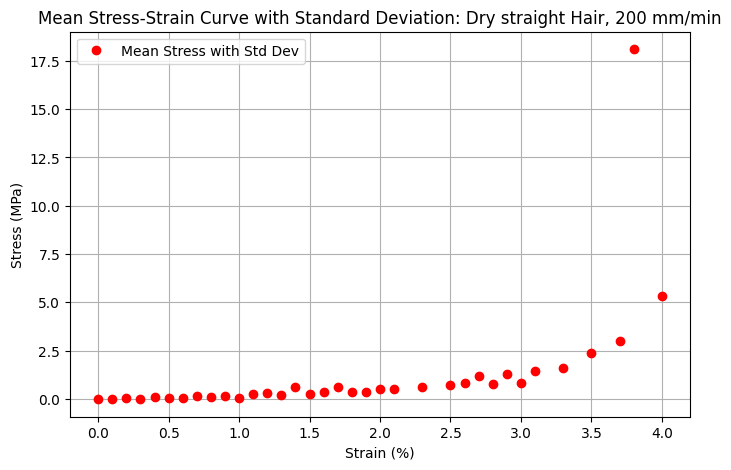

In [21]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry straight Hair, 200 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
strain = mean_df["Strain (%)"].values
stress = mean_df["mean"].values

#Define the exponential model
def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

# 3. Set minimum number of points
# ==========================================

MIN_POINTS_TOE = 18
MIN_POINTS_ELASTIC = 8

# 4. Define possible breakpoints
# ==========================================

# Only search between these strain values
min_breakpoint = 0.01
max_breakpoint = 4.6

possible_breakpoints = np.linspace(min_breakpoint,max_breakpoint,100)

#5. Store results
# ==========================================

results = []


# 6. Test every possible breakpoint
# ==========================================
# loop through each possible breakpoint and fit the toe and elastic regions separately, then calculate the MSE for each fit.
for breakpoint in possible_breakpoints:

    # -----------------------------
    # Divide data
    # -----------------------------

    toe_mask = strain <= breakpoint
    elastic_mask = strain > breakpoint

    toe_strain = strain[toe_mask]
    toe_stress = stress[toe_mask]

    elastic_strain = strain[elastic_mask]
    elastic_stress = stress[elastic_mask]


    # -----------------------------
    # Minimum point requirement
    # -----------------------------

    if len(toe_strain) < MIN_POINTS_TOE:
        continue

    if len(elastic_strain) < MIN_POINTS_ELASTIC:
        continue


    # ==========================================
    # 7. Fit exponential to toe region
    # ==========================================

    try:

        popt_exp, _ = curve_fit(
            exponential,
            toe_strain,
            toe_stress,
            p0=[1, 1],
            maxfev=10000
        )

    except RuntimeError:

        continue


    A, B = popt_exp


    # Predicted toe stresses

    predicted_toe = exponential(
        toe_strain,
        A,
        B
    )


    # ==========================================
    # 8. Fit linear elastic region
    # ==========================================

    linear_coefficients = np.polyfit(
        elastic_strain,
        elastic_stress,
        1
    )

    E = linear_coefficients[0]
    C = linear_coefficients[1]


    # Predicted elastic stresses

    predicted_elastic = (
        E * elastic_strain + C
    )


    # ==========================================
    # 9. Calculate MSE
    # ==========================================

    toe_mse = np.mean(
        (toe_stress - predicted_toe) ** 2
    )

    elastic_mse = np.mean(
        (elastic_stress - predicted_elastic) ** 2
    )


    # ==========================================
    # 10. Combined MSE
    # ==========================================

    total_mse = toe_mse + elastic_mse #total MSE is the sum of the toe and elastic MSEs


    # ==========================================
    # 11. Store results
    # ==========================================

    results.append({
        "breakpoint": breakpoint,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "total_mse": total_mse,
        "A": A,
        "B": B,
        "E": E,
        "C": C,
        "n_toe": len(toe_strain),
        "n_elastic": len(elastic_strain)
    })


#12. Convert results to DataFrame
# ==========================================

results_df = pd.DataFrame(results)


# ==========================================
# 13. Find best breakpoint
# ==========================================

best_index = results_df["total_mse"].idxmin()

best_result = results_df.loc[best_index]


print("\nBEST BREAKPOINT")
print("----------------------")

print(
    "Breakpoint strain:",
    best_result["breakpoint"]
)

print(
    "Toe MSE:",
    best_result["toe_mse"]
)

print(
    "Elastic MSE:",
    best_result["elastic_mse"]
)

print(
    "Total MSE:",
    best_result["total_mse"]
)

print(
    "Number of toe points:",
    int(best_result["n_toe"])
)

print(
    "Number of elastic points:",
    int(best_result["n_elastic"])
)

print("\nToe exponential parameters")

print(
    "A =",
    best_result["A"]
)

print(
    "B =",
    best_result["B"]
)

print("\nElastic linear parameters")

print(
    "E =",
    best_result["E"]
)

print(
    "C =",
    best_result["C"]
)


BEST BREAKPOINT
----------------------
Breakpoint strain: 1.910909090909091
Toe MSE: 0.00967140080737481
Elastic MSE: 12.125021666618705
Total MSE: 12.13469306742608
Number of toe points: 20
Number of elastic points: 15

Toe exponential parameters
A = 0.2606844063010537
B = 0.5471187501093895

Elastic linear parameters
E = 4.301967834890524
C = -10.102106743387544


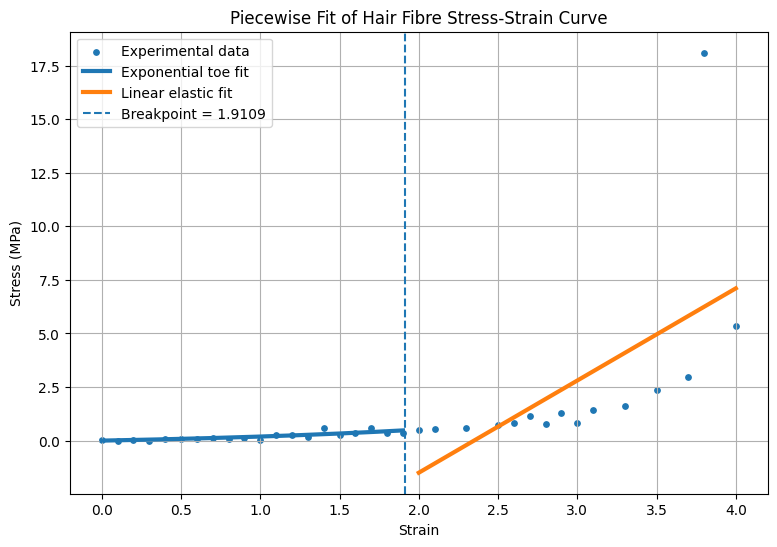

In [23]:
best_breakpoint = best_result["breakpoint"]

toe_mask = strain <= best_breakpoint
elastic_mask = strain > best_breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]


# Exponential fit

A = best_result["A"]
B = best_result["B"]

toe_x = np.linspace(
    toe_strain.min(),
    toe_strain.max(),
    200
)

toe_y = exponential(
    toe_x,
    A,
    B
)


# Linear fit

E = best_result["E"]
C = best_result["C"]

elastic_x = np.linspace(
    elastic_strain.min(),
    elastic_strain.max(),
    200
)

elastic_y = E * elastic_x + C


# Plot

plt.figure(figsize=(9, 6))

plt.scatter(
    strain,
    stress,
    s=15,
    label="Experimental data"
)

plt.plot(
    toe_x,
    toe_y,
    linewidth=3,
    label="Exponential toe fit"
)

plt.plot(
    elastic_x,
    elastic_y,
    linewidth=3,
    label="Linear elastic fit"
)

plt.axvline(
    best_breakpoint,
    linestyle="--",
    label=f"Breakpoint = {best_breakpoint:.4f}"
)

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Piecewise Fit of Hair Fibre Stress-Strain Curve")

plt.legend()
plt.grid(True)

plt.show()

In [24]:
breakpoint = best_breakpoint

toe_mask = strain <= breakpoint
elastic_mask = strain > breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]

# 2. Calculate predicted stress
# ------------------------------------------

def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

predicted_toe = exponential(toe_strain, A, B)
predicted_elastic = E * elastic_strain + C

# 3. Toe-region length
# ------------------------------------------

toe_length = breakpoint - np.min(strain)

# ------------------------------------------
# 4. Stress at transition
# ------------------------------------------

stress_transition_toe = exponential(breakpoint, A, B)
stress_transition_elastic = E * breakpoint + C

# Difference between the two models at the breakpoint
transition_gap = stress_transition_elastic - stress_transition_toe

# 5. Effective toe-region stiffness
# ------------------------------------------

# Derivative of A*(exp(B*strain) - 1)
toe_stiffness_transition = A * B * np.exp(B * breakpoint)

# ------------------------------------------
# 6. Elastic modulus
# ------------------------------------------

elastic_modulus = E

# 7. Correlation and R-squared
# ------------------------------------------

def calculate_metrics(observed, predicted):
    residuals = observed - predicted

    sse = np.sum(residuals ** 2)
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)

    sst = np.sum((observed - np.mean(observed)) ** 2)

    r_squared = 1 - sse / sst if sst > 0 else np.nan

    # Pearson correlation is undefined for constant arrays
    if (
        len(observed) >= 2
        and np.std(observed) > 0
        and np.std(predicted) > 0
    ):
        r = pearsonr(observed, predicted).statistic
    else:
        r = np.nan

    return {
        "r": r,
        "R_squared": r_squared,
        "SSE": sse,
        "MSE": mse,
        "RMSE": rmse,
        "residuals": residuals
    }

toe_metrics = calculate_metrics(toe_stress, predicted_toe)
elastic_metrics = calculate_metrics(elastic_stress, predicted_elastic)

all_stress = np.concatenate([toe_stress, elastic_stress])
all_predicted = np.concatenate([predicted_toe, predicted_elastic])

overall_metrics = calculate_metrics(all_stress, all_predicted)

# ------------------------------------------
# 8. Print results
# ------------------------------------------

print("\n===== HAIR FIBRE ANALYSIS =====")

print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")

print("\nStress at transition:")
print(f"Exponential fit: {stress_transition_toe:.6f}")
print(f"Linear fit:      {stress_transition_elastic:.6f}")
print(f"Transition gap:  {transition_gap:.6f}")

print("\nToe-region stiffness at transition:")
print(f"{toe_stiffness_transition:.6f} stress units per strain unit")

print("\nElastic modulus:")
print(f"{elastic_modulus:.6f} stress units per strain unit")

for name, metrics in [
    ("TOE REGION", toe_metrics),
    ("ELASTIC REGION", elastic_metrics),
    ("OVERALL", overall_metrics)
]:
    print(f"\n{name}")
    print(f"Pearson r: {metrics['r']:.5f}")
    print(f"R-squared: {metrics['R_squared']:.5f}")
    print(f"SSE:       {metrics['SSE']:.6f}")
    print(f"MSE:       {metrics['MSE']:.6f}")
    print(f"RMSE:      {metrics['RMSE']:.6f}")


===== HAIR FIBRE ANALYSIS =====
Breakpoint strain: 1.910909
Toe-region length: 1.910909

Stress at transition:
Exponential fit: 0.480912
Linear fit:      -1.881437
Transition gap:  -2.362349

Toe-region stiffness at transition:
0.405741 stress units per strain unit

Elastic modulus:
4.301968 stress units per strain unit

TOE REGION
Pearson r: 0.84370
R-squared: 0.70761
SSE:       0.193428
MSE:       0.009671
RMSE:      0.098343

ELASTIC REGION
Pearson r: 0.59181
R-squared: 0.35024
SSE:       181.875325
MSE:       12.125022
RMSE:      3.482100

OVERALL
Pearson r: 0.66999
R-squared: 0.44888
SSE:       182.068753
MSE:       5.201964
RMSE:      2.280782
